In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
actual = pd.read_csv('y_test_sel.csv')
predicted = pd.read_csv('deepseek_MIC_predictions.csv')

In [3]:
y_pred = predicted['predicted_mic']

In [4]:
evaluation = pd.DataFrame([{
    'Model': 'Claude-sonnet-5.5',
    'MAE': mean_absolute_error(actual, y_pred),
    'MSE': mean_squared_error(actual, y_pred),
    'RMSE': root_mean_squared_error(actual, y_pred),
    'R2': r2_score(actual, y_pred)
}])

print(evaluation)

               Model         MAE            MSE        RMSE        R2
0  Claude-sonnet-5.5  157.340684  648730.901335  805.438329 -0.018239


In [5]:
evaluation.to_csv('overallresult_deepseek_sel_MIC.csv', index=False)

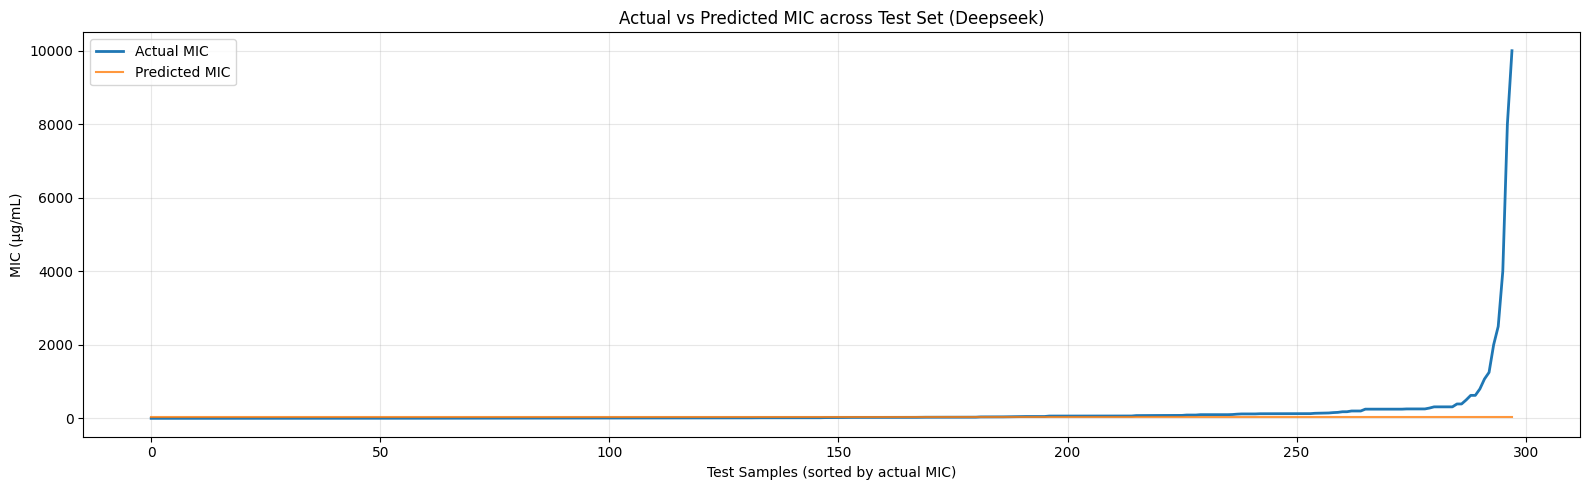

In [6]:
y_true = np.array(actual).ravel()
y_pred = np.array(y_pred).ravel()

sort_idx = np.argsort(y_true)

y_true_sorted = y_true[sort_idx]
y_pred_sorted = y_pred[sort_idx]

plt.figure(figsize=(16, 5))

plt.plot(
    y_true_sorted,
    label='Actual MIC',
    linewidth=2
)

plt.plot(
    y_pred_sorted,
    label='Predicted MIC',
    linewidth=1.5,
    alpha=0.8
)

plt.xlabel('Test Samples (sorted by actual MIC)')
plt.ylabel('MIC (µg/mL)')
plt.title('Actual vs Predicted MIC across Test Set (Deepseek)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

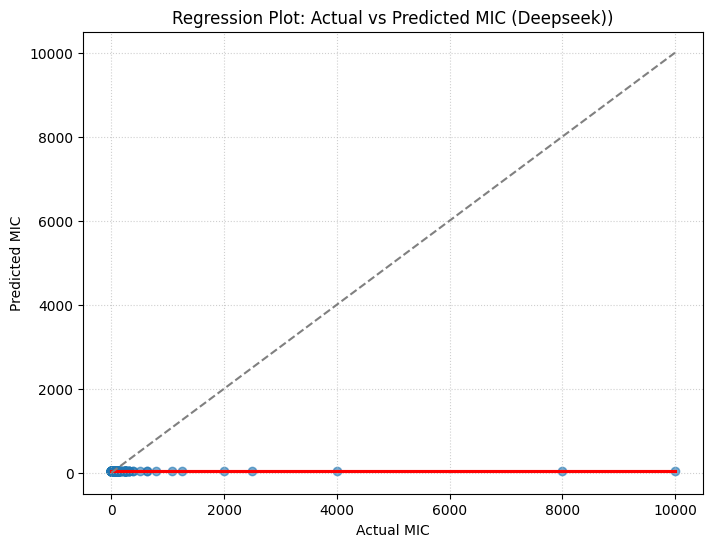

In [7]:
y_actual = actual.iloc[:, 0]

plt.figure(figsize=(8, 6))
sns.regplot(x=y_actual, y=y_pred, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})

max_val = max(y_actual.max(), y_pred.max())
min_val = min(y_actual.min(), y_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='gray', linestyle='--')

plt.xlabel('Actual MIC')
plt.ylabel('Predicted MIC')
plt.title('Regression Plot: Actual vs Predicted MIC (Deepseek))')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [8]:
df_eval = pd.DataFrame({
    'y_true': y_true,
    'y_pred': y_pred
})

In [9]:
df_eval['quantile'] = pd.cut(
    df_eval['y_true'],
    bins=[
        -np.inf,
        np.percentile(y_true, 25),
        np.percentile(y_true, 50),
        np.percentile(y_true, 75),
        np.inf
    ],
    labels=['Q1 (0-25%)', 'Q2 (25-50%)',
            'Q3 (50-75%)', 'Q4 (75-100%)'],
    include_lowest=True
)

In [10]:
results = []

for q, group in df_eval.groupby('quantile', observed=True):
    results.append({
        'Quantile': q,
        'N': len(group),
        'MIC range': f"{group.y_true.min():.2f} - {group.y_true.max():.2f}",
        'MAE': mean_absolute_error(group.y_true, group.y_pred),
        'MSE': mean_squared_error(group.y_true, group.y_pred),
        'RMSE': np.sqrt(mean_squared_error(group.y_true, group.y_pred)),
        'R2': r2_score(group.y_true, group.y_pred)
    })

quantile_results = pd.DataFrame(results)
quantile_results.insert(0, 'Model', 'Deepseek')
display(quantile_results.round(4))

,Model,Quantile,N,MIC range,MAE,MSE,RMSE,R2
0,Deepseek,Q1 (0-25%),76,0.00 - 5.00,48.3013,2.335289e+03,48.3248,-1027.3828
1,Deepseek,Q2 (25-50%),74,5.10 - 20.00,39.6770,1.590290e+03,39.8784,-98.2444
2,Deepseek,Q3 (50-75%),74,22.50 - 78.79,17.1861,3.615724e+02,19.0151,-0.0407
3,Deepseek,Q4 (75-100%),74,80.00 - 10000.00,527.1453,2.608107e+06,1614.9633,-0.1193


In [11]:
quantile_results.to_csv('quantileresult_deepseek_sel_MIC.csv', index=False)

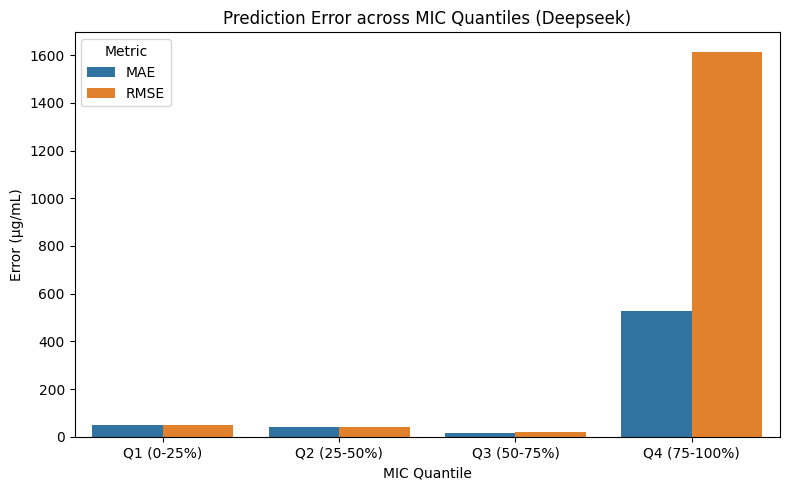

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=quantile_results.melt(
        id_vars='Quantile',
        value_vars=['MAE', 'RMSE'],
        var_name='Metric',
        value_name='Error'
    ),
    x='Quantile',
    y='Error',
    hue='Metric'
)

plt.title('Prediction Error across MIC Quantiles (Deepseek)')
plt.ylabel('Error (µg/mL)')
plt.xlabel('MIC Quantile')
plt.tight_layout()
plt.show()